# Fresh Desk · Model analytics

Recomputes precision, recall, F1, confusion matrices and visualizations for all three classifiers from the saved artifact and supplied validation CSV. No API key or external inference service is used.

**Development evaluation:** this validation set informed tuning; these scores are not independent holdout results. The data are synthetic.

In [1]:
from pathlib import Path
import sys
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'app/model.py').exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from scripts.model_analytics import build_analytics
analytics = build_analytics()
print('Model:', analytics['model_version'])
print('Validation tickets:', analytics['examples'])
print('Schema-valid predictions:', analytics['official_schema_valid_predictions'])

{
  "category": {
    "accuracy": 0.63,
    "macro_f1": 0.6504
  },
  "secondary_category": {
    "accuracy": 0.955,
    "macro_f1": 0.6922
  },
  "is_urgent": {
    "accuracy": 0.975,
    "macro_f1": 0.9313
  }
}
Saved evaluation breakdown to /Users/geemalfernando/Documents/projects/Tensorforge/artifacts/evaluation_breakdown.json


Model: tf-phase2-drive-2.0.0
Validation tickets: 800
Schema-valid predictions: 800


## Model configurations
The three pipelines share word/character TF-IDF features. Primary and urgency use logistic regression; secondary uses a calibrated linear SVM. Thresholds and parameters are frozen in the repository.

In [2]:
import json
settings = json.loads((ROOT / 'configs/training.json').read_text())
display(pd.DataFrame(settings['models']).T)

,estimator,C,class_weight,normalize,char_analyzer,char_ngram_range,threshold
category,logistic_regression,100,balanced,False,char_wb,"[2, 6]",NaN
secondary_category,calibrated_svm,1.0,None,True,char,"[2, 6]",0.2
is_urgent,logistic_regression,40,balanced,True,char,"[2, 5]",0.3


## Overall precision, recall and F1
Macro averages give each supported class equal weight; weighted averages account for class frequency. Accuracy can hide rare-label failures.

,accuracy,macro_precision,macro_recall,macro_f1-score,weighted_precision,weighted_recall,weighted_f1-score
model,,,,,,,
category,0.630,0.6687,0.6516,0.6504,0.6420,0.630,0.6272
secondary_category,0.955,0.9921,0.5660,0.6922,0.9571,0.955,0.9479
is_urgent,0.975,0.9267,0.9361,0.9313,0.9753,0.975,0.9751


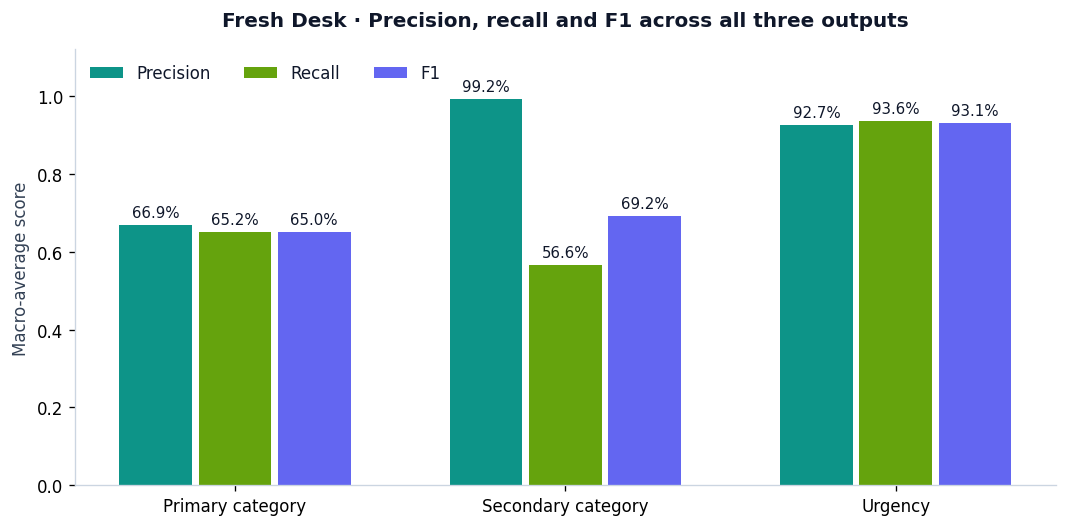

In [3]:
rows = []
for target, report in analytics['classification_reports'].items():
    rows.append({'model': target, 'accuracy': report['accuracy'], **{'macro_' + key: report['macro avg'][key] for key in ['precision','recall','f1-score']}, **{'weighted_' + key: report['weighted avg'][key] for key in ['precision','recall','f1-score']}})
summary = pd.DataFrame(rows).set_index('model')
display(summary.round(4))
display(Image(filename=analytics['figures']['model-summary']))

## Every class: precision, recall, F1 and support
Secondary includes a no-secondary class; not every category has a secondary training label. A score of zero is reported rather than omitted when a supported class receives no correct predictions.


category


,precision,recall,f1-score,support
account_promo,0.7778,0.6806,0.7259,72.0
app_technical,0.7381,0.4844,0.5849,64.0
delivery_delay,0.6519,0.7333,0.6902,120.0
food_quality,0.6316,0.4286,0.5106,56.0
general_inquiry,0.5536,0.7750,0.6458,40.0
lost_item,0.5273,0.7250,0.6105,40.0
order_missing_wrong,0.4324,0.3333,0.3765,96.0
payment_refund,0.5108,0.6597,0.5758,144.0
ride_trip_issue,0.8182,0.7232,0.7678,112.0
safety_conduct,0.7143,0.6250,0.6667,32.0



secondary_category


,precision,recall,f1-score,support
__none__,0.9524,1.0000,0.9756,720.0
app_technical,1.0000,0.3333,0.5000,9.0
delivery_delay,1.0000,0.4444,0.6154,9.0
order_missing_wrong,1.0000,0.3333,0.5000,9.0
payment_refund,1.0000,0.6923,0.8182,26.0
ride_trip_issue,1.0000,0.5926,0.7442,27.0
macro avg,0.9921,0.5660,0.6922,800.0
weighted avg,0.9571,0.9550,0.9479,800.0



is_urgent


,precision,recall,f1-score,support
false,0.9875,0.9847,0.9861,720.0
true,0.8659,0.8875,0.8765,80.0
macro avg,0.9267,0.9361,0.9313,800.0
weighted avg,0.9753,0.9750,0.9751,800.0


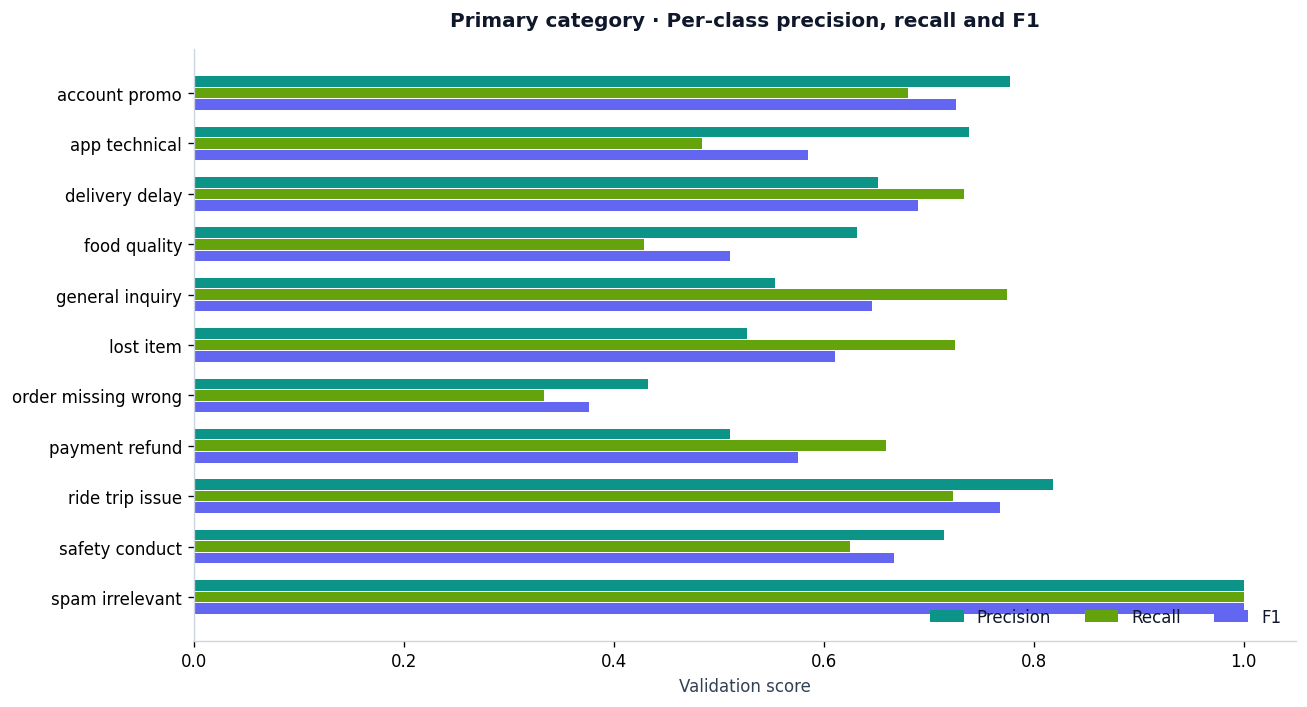

In [4]:
for target, report in analytics['classification_reports'].items():
    print('\n' + target)
    display(pd.DataFrame({label: values for label, values in report.items() if isinstance(values, dict)}).T.round(4))
display(Image(filename=analytics['figures']['primary-class-scores']))

## Confusion matrices
Rows are true labels; columns are predictions. Counts use final API predictions after consistency and category precedence rules.

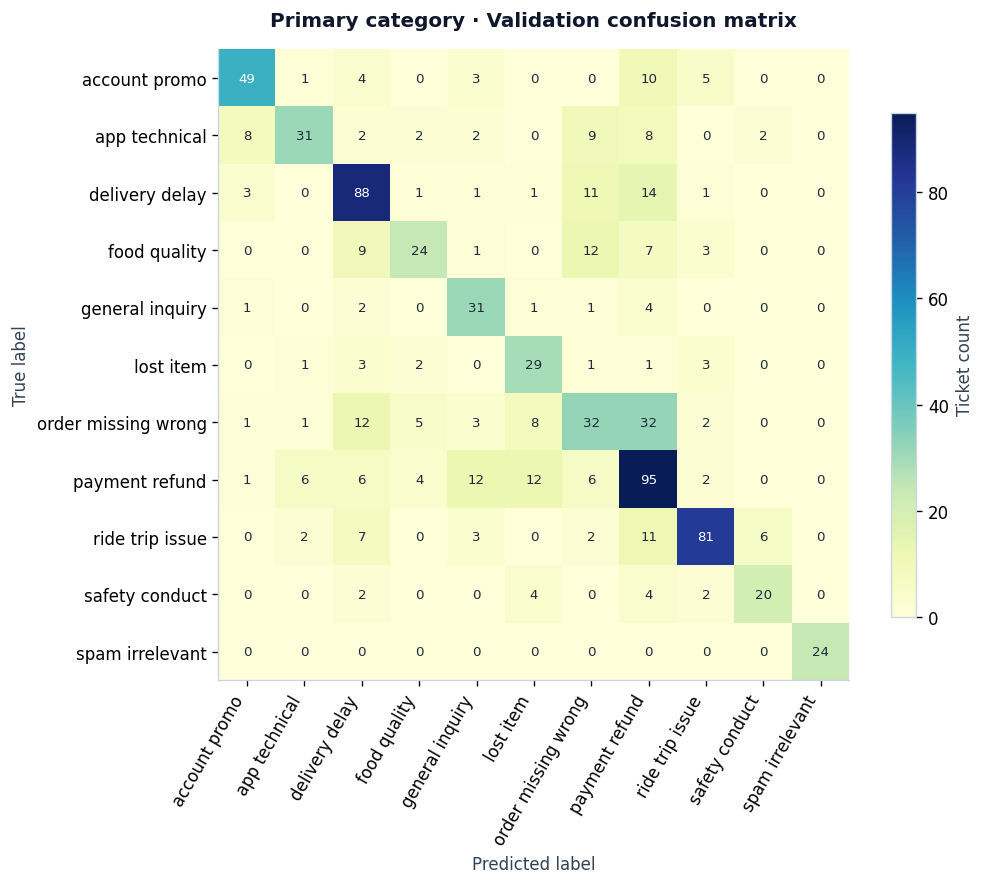

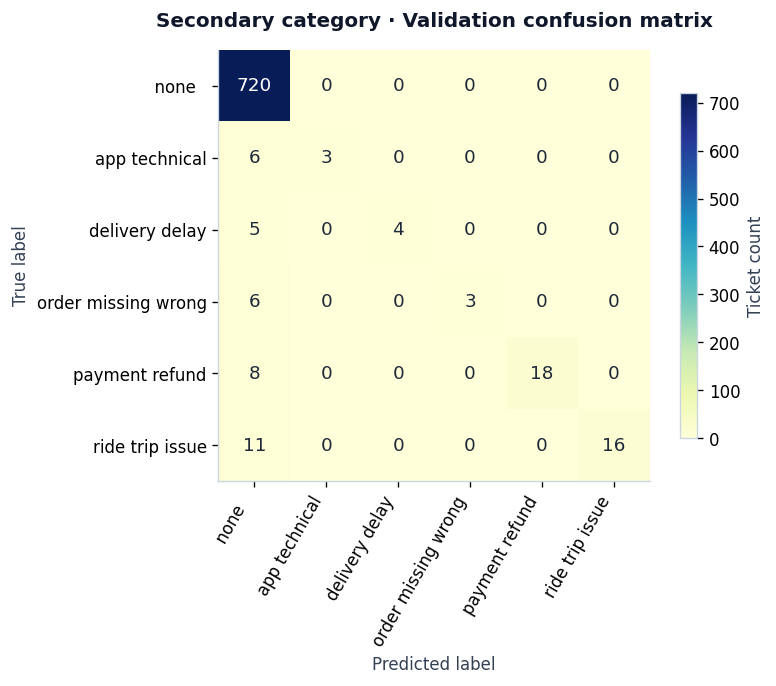

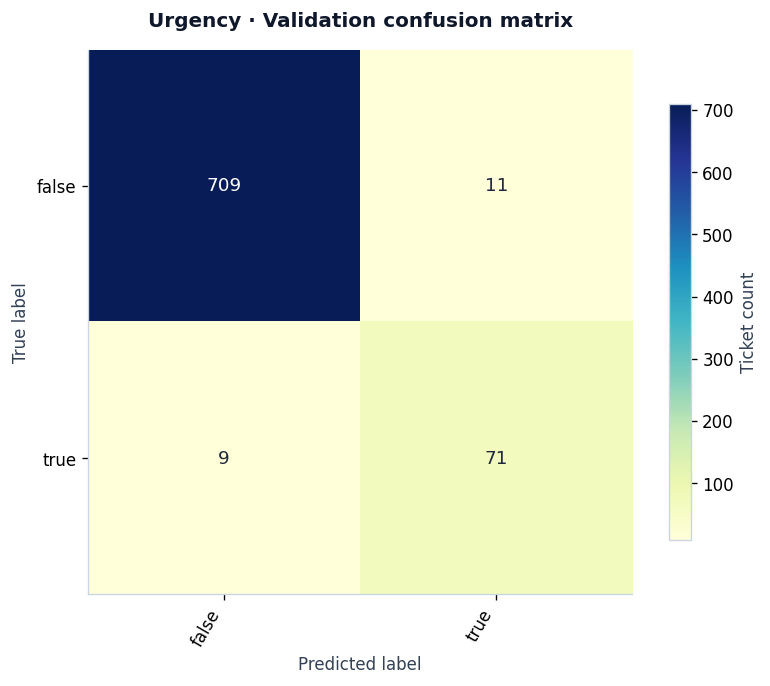

In [5]:
for target in ['category','secondary_category','is_urgent']:
    display(Image(filename=analytics['figures'][target + '-confusion']))

## Language analysis
Small language groups are uncertain. These results measure the synthetic workshop split and do not establish accuracy on native speakers’ real support messages.

,count,accuracy,macro_f1
en,280.0,0.5393,0.5849
mixed,20.0,0.5500,0.3699
si,160.0,0.4625,0.4924
singlish,200.0,0.9050,0.9098
ta,120.0,0.6167,0.5712
tanglish,20.0,0.6500,0.5610


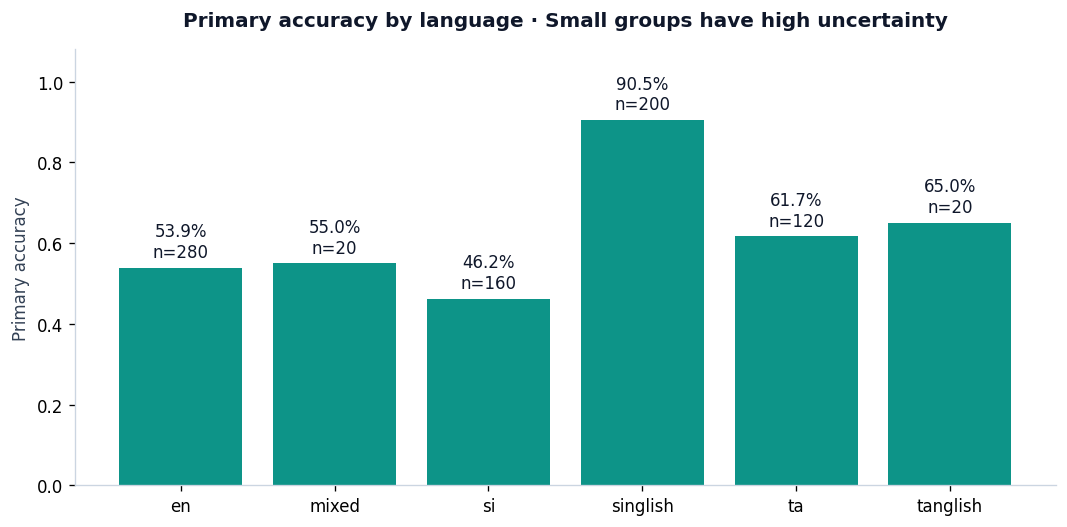

In [6]:
display(pd.DataFrame(analytics['category_by_language']).T.round(4))
display(Image(filename=analytics['figures']['language-accuracy']))

## Urgency precision–recall tradeoff
The configured operating cutoff is 30%. This plot is before the spam rule; the earlier score tables include the rule.

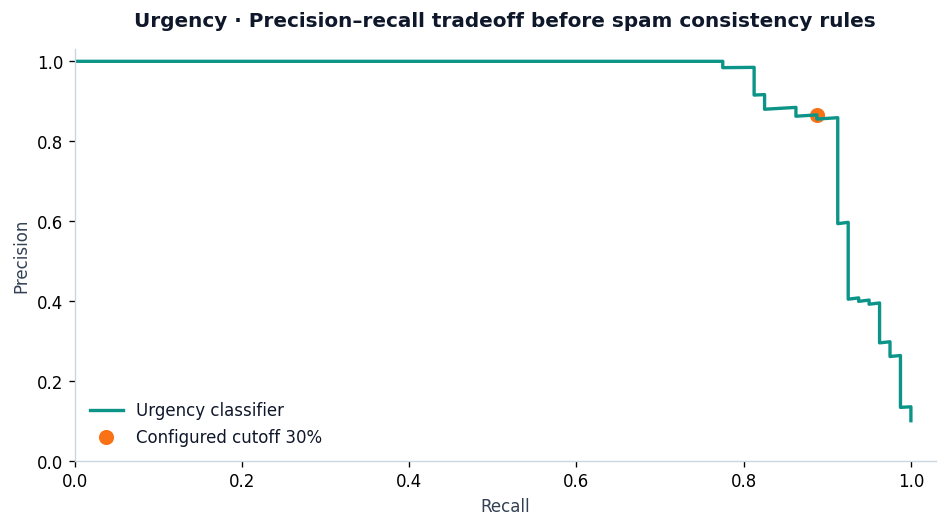

In [7]:
display(Image(filename=analytics['figures']['urgency-precision-recall']))

## Human approval and findings
Primary confidence below 50% or a message of three or fewer words recommends human review. Urgent tickets also enter the support queue. Support staff inspect the saved probabilities and may accept routing or explain an override. The raw model prediction is preserved. Primary probabilities are not independently calibrated.

The primary classifier remains the main limitation. The separate judges’ holdout dataset is the independent test.

In [8]:
print('Human-review recommendations:', analytics['human_review_count'], '/', analytics['examples'])
display(pd.DataFrame(analytics['top_category_confusions']))
print('Exported Markdown:', ROOT / 'docs/model-analytics.md')
print('Exported PNG/SVG figures:', ROOT / 'docs/analytics')

Human-review recommendations: 485 / 800


,actual,predicted,count
0,order_missing_wrong,payment_refund,32
1,delivery_delay,payment_refund,14
2,order_missing_wrong,delivery_delay,12
3,food_quality,order_missing_wrong,12
4,payment_refund,lost_item,12
5,payment_refund,general_inquiry,12
6,delivery_delay,order_missing_wrong,11
7,ride_trip_issue,payment_refund,11
8,account_promo,payment_refund,10
9,app_technical,order_missing_wrong,9


Exported Markdown: /Users/geemalfernando/Documents/projects/Tensorforge/docs/model-analytics.md
Exported PNG/SVG figures: /Users/geemalfernando/Documents/projects/Tensorforge/docs/analytics
